# Overlapping audio: model and experiments
Core preprocessing, models, masked loss, scorer, training loop and temporal policy are written out below. They match production functions. PANNs Cnn14 is a pinned pretrained dependency with its upstream MIT notice.

Original cloud and twelve-fit CPU studies are recorded experiments. This notebook also repeats exactly one existing control configuration on authentic train/validation features to verify full-data training reproducibility. That replay is not a new selection candidate and never opens test. Its artifact path is fresh. Production remains the validation-selected five-second head with box3.

In [1]:
from pathlib import Path
import sys, json, math, hashlib, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
CACHE=ROOT/'data/features/five-second-cache'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=4)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def report(name): return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
import torch
from torch import nn
from urllib.request import urlopen
from overlap_audio.natural import OFFICIAL_CLASSES
from overlap_audio.postprocess import aligned_cache, validate_bundle
RATE=32000
WEIGHT_URL='https://zenodo.org/records/3987831/files/Cnn14_mAP%3D0.431.pth?download=1'
WEIGHT_MD5='541141fa2ee191a88f24a3219fff024e'
torch.set_num_threads(2)
print({'torch':str(torch.__version__),'threads':torch.get_num_threads(),'encoder_allocated_locally':False})

{'torch': '2.14.0+cpu', 'threads': 2, 'encoder_allocated_locally': False}


## Native context and frozen backbone
Five-second windows are centered on labeled seconds at 32 kHz. The loader verifies weights and state. It is defined below, but no large encoder is allocated locally.

In [3]:
def windows(wave, seconds, context_seconds=5):
    """Five-second context or central-second ablation at encoder's native rate."""
    if context_seconds not in [1,5]:
        raise ValueError('Supported context lengths are one or five seconds')
    if wave.ndim != 1 or not len(wave) or not np.isfinite(wave).all():
        raise ValueError('Expected nonempty finite mono waveform')
    result = []
    for second in seconds:
        start = (second-context_seconds//2)*RATE
        stop = start+context_seconds*RATE
        result.append(np.pad(wave[max(0,start):min(len(wave),stop)],
                             (max(0,-start), max(0,stop-len(wave)))))
    return torch.from_numpy(np.stack(result))

def encoder(weights, device):
    """Load the externally pinned original PANNs architecture and state strictly."""
    # Import pinned upstream modules without panns_inference.__init__, whose
    # config performs an unverified shell download of irrelevant AudioSet labels.
    from overlap_audio._panns.models import Cnn14
    weights = Path(weights)
    if not weights.exists():
        weights.parent.mkdir(parents=True, exist_ok=True)
        temporary = weights.with_suffix('.part')
        with urlopen(WEIGHT_URL, timeout=90) as response, temporary.open('wb') as handle:
            for block in iter(lambda: response.read(1024*1024), b''):
                handle.write(block)
        temporary.replace(weights)
    digest = hashlib.md5()
    with weights.open('rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''):
            digest.update(block)
    if digest.hexdigest() != WEIGHT_MD5:
        raise ValueError('Pretrained weight checksum mismatch')
    model = Cnn14(RATE, 1024, 320, 64, 50, 14000, 527)
    state = torch.load(weights, map_location='cpu', weights_only=True)
    model.load_state_dict(state['model'], strict=True)
    model.eval().requires_grad_(False)
    return model.to(device)

## Models and masked soft-label objective
The scratch CNN is the earlier comparison. Transfer heads consume 2,048-dimensional frozen embeddings and predict 17 classes. Unknown annotations contribute no loss.

In [4]:
class StrongCNN(nn.Module):
    def __init__(self, classes=4, width=24):
        super().__init__()
        blocks=[]
        channels=1
        for output in [width,width*2,width*4]:
            blocks += [nn.Conv2d(channels,output,3,padding=1),nn.BatchNorm2d(output),nn.GELU(),
                       nn.Conv2d(output,output,3,padding=1),nn.BatchNorm2d(output),nn.GELU(),nn.MaxPool2d(2)]
            channels=output
        self.features=nn.Sequential(*blocks)
        self.head=nn.Sequential(nn.Dropout(.25),nn.Linear(channels*8,classes))

    def forward(self, spec):
        # Per-example log-power normalization avoids raw gain shortcuts.
        spec=(spec-spec.mean(dim=(-2,-1),keepdim=True))/(spec.std(dim=(-2,-1),keepdim=True)+1e-5)
        features=self.features(spec)
        pooled=nn.functional.adaptive_avg_pool2d(features,(4,1)).flatten(1)
        maximum=nn.functional.adaptive_max_pool2d(features,(4,1)).flatten(1)
        return self.head(torch.cat([pooled,maximum],dim=1))

class Head(nn.Module):
    def __init__(self, classes, hidden=0, dropout=.3):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(2048,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,classes)) if hidden else nn.Linear(2048,classes)

    def forward(self, x):
        return self.layers(x)

def masked_loss(logits, target, mask, pos_weight):
    loss = nn.functional.binary_cross_entropy_with_logits(logits,target,reduction='none',pos_weight=pos_weight)
    return (loss*mask).sum()/mask.sum().clamp_min(1)

def predict_head(model, x):
    model.eval()
    with torch.inference_mode():
        return torch.cat([torch.sigmoid(model(batch)) for batch in x.split(256)]).cpu()

## Scoring
AP handles complete tied thresholds. Unsupported classes have AP undefined. Supported macro AP and all-observed-class F1 are reported separately.

In [5]:
def f1_per_class(targets, predictions):
    tp=(targets*predictions).sum(0);fp=((1-targets)*predictions).sum(0);fn=(targets*(1-predictions)).sum(0)
    return 2*tp/(2*tp+fp+fn).clamp_min(1)

def average_precision(target, scores):
    positives=float(target.sum())
    if not positives: return None
    # Sort once and evaluate only complete tied thresholds (O(n log n)).
    order=torch.argsort(scores,descending=True,stable=True)
    ordered_scores=scores[order]
    cumulative=target[order].cumsum(0)
    ends=torch.ones(len(scores),dtype=torch.bool,device=scores.device)
    ends[:-1]=ordered_scores[:-1]!=ordered_scores[1:]
    indices=torch.arange(1,len(scores)+1,device=scores.device)[ends]
    correct=cumulative[ends]
    increments=torch.diff(correct,prepend=torch.zeros(1,device=correct.device))
    ap=((increments/positives)*(correct/indices)).sum()
    return min(1.,max(0.,float(ap)))

def scores(target,probability,mask,thresholds,classes):
    if target.ndim!=2 or probability.shape!=target.shape or mask.shape!=target.shape or thresholds.ndim!=1 or len(thresholds)!=target.shape[1] or len(classes)!=target.shape[1]:
        raise ValueError('Metric input shapes or class order are inconsistent')
    if not all(torch.isfinite(value).all() for value in [target,probability,mask,thresholds]) or not ((target>=0)&(target<=1)).all() or not ((probability>=0)&(probability<=1)).all() or not ((thresholds>=0)&(thresholds<=1)).all() or not ((mask==0)|(mask==1)).all():
        raise ValueError('Metrics require finite probabilities and binary observation masks')
    hard=(target>.5).float()
    prediction=(probability>=thresholds).float()
    per_class=[]
    for k,label in enumerate(classes):
        observed=mask[:,k].bool()
        y,p=hard[observed,k],probability[observed,k]
        f1=float(f1_per_class(y[:,None],(p>=thresholds[k]).float()[:,None])[0]) if len(y) else None
        per_class.append({'class':label,'positive':int(y.sum()),'observed':len(y),'f1':f1,
                          'ap':average_precision(y,p) if len(y) else None})
    supported=[r for r in per_class if r['positive']>0]
    official=[r for r in supported if r['class'] in OFFICIAL_CLASSES]
    observed_classes=[r for r in per_class if r['observed']>0]
    official_observed=[r for r in observed_classes if r['class'] in OFFICIAL_CLASSES]
    tp=float((hard*prediction*mask).sum());fp=float(((1-hard)*prediction*mask).sum());fn=float((hard*(1-prediction)*mask).sum())
    average=lambda rows,key:float(np.mean([r[key] for r in rows])) if rows else None
    return {'macro_ap_supported':average(supported,'ap'),
            'macro_f1_supported':average(supported,'f1'),
            'macro_f1_all_observed_classes':average(observed_classes,'f1'),
            'official_class_macro_f1_supported':average(official,'f1'),
            'official_class_macro_f1_all_observed_classes':average(official_observed,'f1'),
            'micro_f1':2*tp/max(1.,2*tp+fp+fn) if mask.sum() else None,'per_class':per_class,
            'unsupported_classes':[r['class'] for r in per_class if not r['positive']]}

## Actual training loop
Training moments and positive weights never use validation. AdamW, deterministic seeds, gradient clipping, finite checks, checkpoint selection and plateau stopping are visible.

In [6]:
def fit_head(x,y,m,vx,vy,vm,classes,config,seed,epochs=80,device='cuda'):
    """Only x/y/m are training inputs; checkpoint moments never use vx."""
    torch.manual_seed(seed)
    mean=x.mean(0);std=x.std(0,unbiased=False).clamp_min(.01)
    features=((x-mean)/std).to(device);validation=((vx-mean)/std).to(device)
    target,mask=y.to(device),m.to(device)
    positive=((target>.5)*mask).sum(0);weight=((mask.sum(0)-positive)/positive.clamp_min(1)).clamp(1,20)
    model=Head(len(classes),config['hidden'],config['dropout']).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    generator=torch.Generator().manual_seed(seed);best=-1.;best_epoch=0;history=[]
    for epoch in range(epochs):
        model.train();total=0.
        for ids in torch.randperm(len(features),generator=generator).split(128):
            loss=masked_loss(model(features[ids]),target[ids],mask[ids],weight)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite learned-head loss')
            optimizer.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True);optimizer.step()
            total+=float(loss.detach())*len(ids)
        probability=predict_head(model,validation)
        value=scores(vy,probability,vm,torch.full((len(classes),),.5),classes)['macro_ap_supported']
        if value is None:raise ValueError('No supported validation classes')
        history.append({'epoch':epoch+1,'loss':total/len(features),'validation_ap':value})
        if value>best:
            best=value;best_epoch=epoch+1;state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        if epoch+1>=20 and epoch+1-best_epoch>=12:break
    return {'state_dict':state,'config':config,'classes':classes,'mean':mean,'std':std,'seed':seed,
            'sample_rate':RATE,'context_seconds':5}, {'seed':seed,'config':config,'best_epoch':best_epoch,'validation_ap':best,
             'history':history,'stop':'validation_plateau' if epoch+1>=20 and epoch+1-best_epoch>=12 else 'epoch_limit'}

## Recording-safe temporal policy
Only probabilities, recording IDs and seconds enter filtering. Boundaries and gaps reset it. Selected box3 adds one future second to native context, for three seconds of total lookahead.

In [7]:
def checked_probabilities(probability):
    p=np.asarray(probability,dtype=np.float32)
    if p.ndim!=2 or not len(p) or not np.isfinite(p).all() or not ((p>=0)&(p<=1)).all():
        raise ValueError('Expected nonempty finite probability matrix')
    return p

def convex_mix(probabilities,weights):
    values=np.asarray(probabilities,dtype=np.float32)
    w=np.asarray(weights,dtype=np.float64)
    if values.ndim!=3 or w.shape!=(len(values),) or not np.isfinite(w).all() or (w<0).any() or not np.isclose(w.sum(),1,atol=1e-8,rtol=0):
        raise ValueError('Ensemble weights must be finite, nonnegative and sum to one')
    for p in values:checked_probabilities(p)
    return np.clip(np.einsum('k,knc->nc',w,values),0,1).astype(np.float32)

def temporal_filter(probability,record_ids,seconds,spec):
    """No targets/masks enter filtering. Never cross records or missing seconds."""
    p=checked_probabilities(probability);ids=np.asarray(record_ids);t=np.asarray(seconds)
    if ids.shape!=(len(p),) or t.shape!=(len(p),) or not np.isfinite(t).all() or (t<0).any() or not (t==np.floor(t)).all() or any(not str(x) for x in ids):
        raise ValueError('Invalid recording/time alignment')
    if np.any((ids[1:]==ids[:-1])&(t[1:]<=t[:-1])):raise ValueError('Recording seconds must increase strictly')
    kind=spec.get('kind')
    if kind not in ['none','box','ewma']:raise ValueError('Unknown temporal filter')
    width=spec.get('width',1);alpha=spec.get('alpha',1.)
    if kind=='box' and (not isinstance(width,int) or width<1 or width%2!=1):raise ValueError('Box width must be a positive odd integer')
    if kind=='ewma' and (not math.isfinite(alpha) or not 0<alpha<=1):raise ValueError('EWMA alpha must be in (0,1]')
    if kind=='none':return p.copy()
    edges=np.r_[0,np.where((ids[1:]!=ids[:-1])|(t[1:]!=t[:-1]+1))[0]+1,len(p)]
    output=np.empty_like(p)
    for lo,hi in zip(edges[:-1],edges[1:]):
        block=p[lo:hi].astype(np.float64)
        if kind=='box':
            cumulative=np.vstack([np.zeros((1,p.shape[1])),block.cumsum(0)])
            center=np.arange(len(block));left=np.maximum(0,center-width//2);right=np.minimum(len(block),center+width//2+1)
            output[lo:hi]=(cumulative[right]-cumulative[left])/(right-left)[:,None]
        else:
            state=block[0];output[lo]=state
            for index in range(1,len(block)):
                state=alpha*block[index]+(1-alpha)*state;output[lo+index]=state
    return np.clip(output,0,1)

def apply_policy(component_probabilities,policy,record_ids,seconds):
    branches=[]
    for branch in policy['branches']:
        p=convex_mix(component_probabilities,branch['weights'])
        for spec in branch.get('filters',[]):p=temporal_filter(p,record_ids,seconds,spec)
        branches.append(p)
    p=convex_mix(np.stack(branches),policy['mix_weights'])
    for spec in policy.get('filters',[]):p=temporal_filter(p,record_ids,seconds,spec)
    return p

def component_predictions(component,features,device='cpu'):
    x=torch.as_tensor(features,dtype=torch.float32)
    count=len(component['classes']);mean=component['mean'];std=component['std']
    if x.ndim!=2 or x.shape[1]!=2048 or mean.shape!=(2048,) or std.shape!=(2048,) or not torch.isfinite(x).all() or not torch.isfinite(mean).all() or not torch.isfinite(std).all() or not (std>0).all():
        raise ValueError('Invalid component features or normalization')
    model=Head(count,component['config']['hidden'],component['config'].get('dropout',.3)).to(device);model.load_state_dict(component['state_dict'])
    return predict_head(model,((x-mean)/std).to(device)).numpy()

In [8]:
metadata=json.loads((CACHE/'metadata.json').read_text(encoding='utf-8'))
tx,ty,tm,train_ids,train_seconds=aligned_cache(CACHE,'train',metadata)
vx,vy,vm,val_ids,val_seconds=aligned_cache(CACHE,'validation',metadata)
print({'train_seconds':len(tx),'validation_seconds':len(vx),'classes':len(metadata['classes']),'feature_width':tx.shape[1],'recording_overlap':len(set(train_ids)&set(val_ids))})
assert set(train_ids).isdisjoint(set(val_ids))

{'train_seconds': 6838, 'validation_seconds': 2163, 'classes': 17, 'feature_width': 2048, 'recording_overlap': 0}


## Genuine fixed-configuration replay
Seed 42/control is fixed in advance. It repeats V6, not a favorable seed search, and leaves the deployment choice unchanged.

In [9]:
replay_config={'name':'control','hidden':256,'lr':.0003,'dropout':.3,'weight_decay':.01}
started=time.time()
replayed,replay_history=fit_head(*[torch.from_numpy(a) for a in (tx,ty,tm,vx,vy,vm)],metadata['classes'],replay_config,seed=42,epochs=80,device='cpu')
replay_path=ROOT/'models'/('notebook-replay-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
replay_path.mkdir(); torch.save(replayed,replay_path/'seed-42.pt')
recorded_head=torch.load(ROOT/'models/learned-v6-cpu/control/seed-42.pt',map_location='cpu',weights_only=True)
difference=max(float((replayed['state_dict'][k]-recorded_head['state_dict'][k]).abs().max()) for k in replayed['state_dict'])
display(pd.DataFrame([{'seed':42,'best_epoch':replay_history['best_epoch'],'validation_AP':replay_history['validation_ap'],'state_max_difference':difference,'runtime_seconds':time.time()-started}]))
assert difference==0

,seed,best_epoch,validation_AP,state_max_difference,runtime_seconds
0,42,1,0.467208,0.0,67.63185


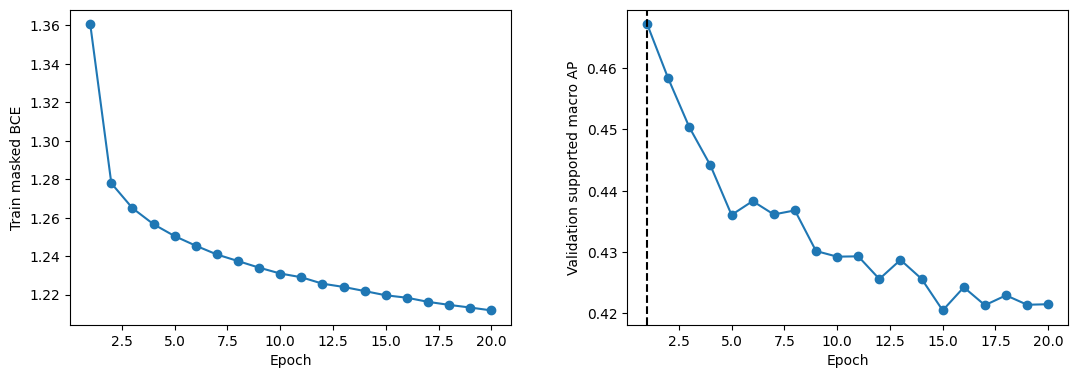

In [10]:
history=pd.DataFrame(replay_history['history'])
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(history['epoch'],history['loss'],marker='o'); axes[0].set(xlabel='Epoch',ylabel='Train masked BCE')
axes[1].plot(history['epoch'],history['validation_ap'],marker='o'); axes[1].axvline(replay_history['best_epoch'],color='black',linestyle='--'); axes[1].set(xlabel='Epoch',ylabel='Validation supported macro AP')
show(fig,'audio_training_replay.png')

## Recorded comparisons
Saved run evidence below includes failed central-context, lower-rate and regularization hypotheses. Missing test results are never filled with invented scores.

In [11]:
transfer=report('transfer-results.json')
rows=[{'model':'Scratch CNN','validation_AP':transfer['scratch_baseline']['validation_macro_ap'],'observed_test_AP':transfer['scratch_baseline']['test_validation_thresholds']['macro_ap_supported']}]
for name,run in transfer['contexts'].items():
    rows.append({'model':name,'validation_AP':run['validation_macro_ap'],'observed_test_AP':run['observed_holdout']['test_validation_thresholds']['macro_ap_supported']})
selected=report('postprocess-v5-selection.json'); observed=report('postprocess-v5-observed-holdout.json')
rows.append({'model':'Selected five-second + box3','validation_AP':selected['selected_validation_ap'],'observed_test_AP':observed['selected']['macro_ap_supported']})
display(pd.DataFrame(rows))
study=report('five-second-learned-v6-selection.json')
comparison=pd.DataFrame([{'configuration':r['config']['name'],'ensemble_validation_AP':r['equal_seed_ensemble_validation_ap'],'seed_AP_mean':r['individual_seed_mean_ap'],'seed_AP_SD':r['individual_seed_std_ap']} for r in study['candidates']])
display(comparison)

,model,validation_AP,observed_test_AP
0,Scratch CNN,0.415523,0.376170
1,five_second,0.470088,0.395376
2,one_second,0.412886,0.336932
3,one_second_lower_lr,0.414323,0.336843
4,Selected five-second + box3,0.476702,0.402975


,configuration,ensemble_validation_AP,seed_AP_mean,seed_AP_SD
0,control,0.459978,0.455856,0.010211
1,slower,0.459589,0.458375,0.010088
2,dropout,0.458951,0.457569,0.006699
3,decay,0.459291,0.457478,0.006737


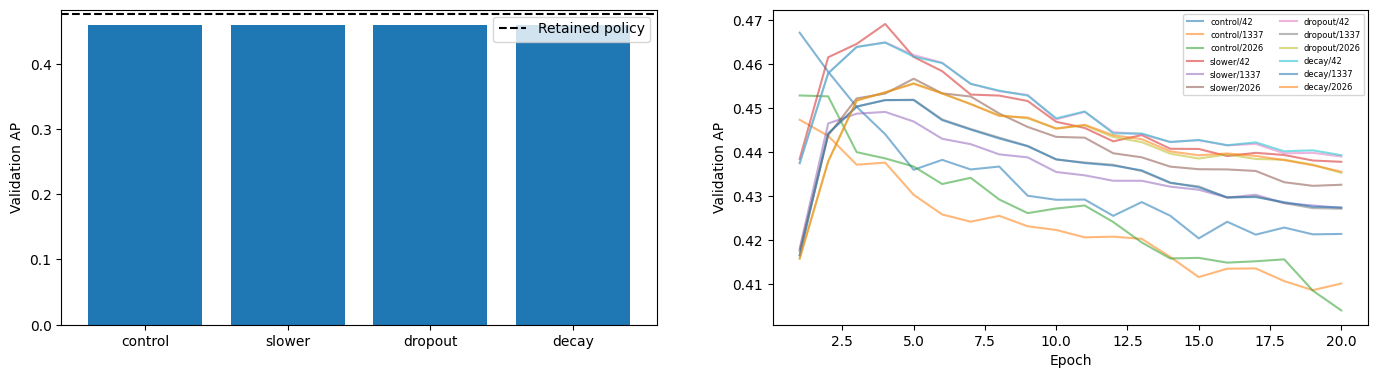

,learned_weight,validation_ap
0,0.00,0.476702
1,0.25,0.473545
2,0.50,0.470274
3,0.75,0.463140
4,1.00,0.466589


In [12]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].bar(comparison['configuration'],comparison['ensemble_validation_AP']); axes[0].axhline(study['prior_validation_ap'],color='black',linestyle='--',label='Retained policy'); axes[0].set(ylabel='Validation AP'); axes[0].legend()
for candidate in study['candidates']:
    for fit in candidate['fits']:
        axes[1].plot([r['epoch'] for r in fit['history']],[r['validation_ap'] for r in fit['history']],alpha=.55,label=candidate['config']['name']+'/'+str(fit['seed']))
axes[1].set(xlabel='Epoch',ylabel='Validation AP'); axes[1].legend(fontsize=6,ncol=2)
show(fig,'audio_all_head_curves.png')
display(pd.DataFrame(study['mixtures']))

## Actual saved-checkpoint inference on validation
The visible head and policy replay the production artifact. No encoder allocation or test rescoring occurs.

In [13]:
checkpoint=torch.load(ROOT/'models/postprocess-v5/selected.pt',map_location='cpu',weights_only=True)
validate_bundle(checkpoint)
raw=np.stack([component_predictions(c,vx) for c in checkpoint['components']])
probability=apply_policy(raw,checkpoint['policy'],val_ids,val_seconds)
replayed_metrics=scores(torch.from_numpy(vy),torch.from_numpy(probability),torch.from_numpy(vm),checkpoint['thresholds'],metadata['classes'])
print({'replayed_validation_AP':replayed_metrics['macro_ap_supported'],'frozen_validation_AP':selected['selected_validation_ap'],'lookahead_seconds':checkpoint['lookahead_seconds']})
assert replayed_metrics['macro_ap_supported']==selected['selected_validation_ap']

{'replayed_validation_AP': 0.4767020190677916, 'frozen_validation_AP': 0.4767020190677916, 'lookahead_seconds': 3}


The control replay reproduces its recorded state exactly, but it is not the production winner. Twelve new fits failed to beat the earlier head with box3. The test was already observed; V5 aggregate was opened after V6 protocol freeze but before V6 selection completed. No V6 rule changed in response. This is a plateau for the tested grid, not proof of optimality.